# Mini-Bengio: generalization to unseen word combinations

**Classroom demonstration (15–25 minutes, CPU only)** — inspired by Bengio, Ducharme, Vincent & Jauvin, *A Neural Probabilistic Language Model* (JMLR, 2003).

**Research question.** Can a neural next-word predictor assign high probability to an *unseen combination of known words*? Compare (A) a count-based trigram with bigram back-off and (B) a neural trigram with learned embeddings, one `tanh` hidden layer, and a softmax distribution.

**How to run:** Open this `.ipynb` in Google Colab or Jupyter; select **Runtime → Run all**. It uses `torch`, `numpy` and `matplotlib` (preinstalled on Colab); **no GPU, API key or external data**. A `.py` version is also provided.

This is an **illustration**, not a faithful reproduction of the original paper's performance comparisons. The corpus is deliberately artificial, the baseline is simplistic, and the task is very easy for a neural model.


In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(1)
print('PyTorch version:', torch.__version__)


PyTorch version: 2.10.0+cpu


## 1. Prepare the training/test split
The entire language has just 24 possible triples. We deliberately remove six **subject–relation combinations**, while ensuring every individual word is observed during training.

In [2]:
# Eight subjects, three relations, six possible target words = 17 words total.
animals = ["cat", "dog", "fox", "wolf"]
vehicles = ["car", "bus", "van", "train"]
relations = ["needs", "has", "moves"]
endings = {
    "animal":  {"needs": "food", "has": "fur", "moves": "walks"},
    "vehicle": {"needs": "fuel", "has": "wheels", "moves": "rolls"},
}

# Hold out one relation per chosen subject. Every WORD remains in training.
held_out_contexts = {
    ("dog", "needs"), ("wolf", "has"), ("fox", "moves"),
    ("bus", "needs"), ("train", "has"), ("van", "moves"),
}

all_triples = [
    (s, r, endings["animal" if s in animals else "vehicle"][r])
    for s in animals + vehicles for r in relations
]
train = [row for row in all_triples if row[:2] not in held_out_contexts]
test  = [row for row in all_triples if row[:2] in held_out_contexts]

vocab = animals + vehicles + relations + list(endings["animal"].values()) + list(endings["vehicle"].values())
word_id = {w: i for i, w in enumerate(vocab)}
assert len(vocab) == 17 and len(train) == 18 and len(test) == 6
assert set(w for triple in test for w in triple).issubset(set(w for triple in train for w in triple))

print(f'Vocabulary: {len(vocab)} words | Train: {len(train)} triples | Test: {len(test)} unseen triples')
print('TRAIN:')
for s, r, w in train: print(f'  {s:<6} {r:<6} {w}')
print('HELD OUT:')
for s, r, w in test: print(f'  {s:<6} {r:<6} {w}')


Vocabulary: 17 words | Train: 18 triples | Test: 6 unseen triples
TRAIN:
  cat    needs  food
  cat    has    fur
  cat    moves  walks
  dog    has    fur
  dog    moves  walks
  fox    needs  food
  fox    has    fur
  wolf   needs  food
  wolf   moves  walks
  car    needs  fuel
  car    has    wheels
  car    moves  rolls
  bus    has    wheels
  bus    moves  rolls
  van    needs  fuel
  van    has    wheels
  train  needs  fuel
  train  moves  rolls
HELD OUT:
  dog    needs  food
  fox    moves  walks
  wolf   has    fur
  bus    needs  fuel
  van    moves  rolls
  train  has    wheels


## 2. Count-based baseline
The trigram model looks up the exact two-word context. For the six unseen contexts it backs off to a one-word context (the relation), where the correct ending competes with another ending.

In [3]:
trigram_counts = Counter(train)
bigram_counts = Counter((r, w) for _, r, w in train)

def count_probability(subject, relation, target):
    # Full trigram context (subject, relation) if observed; otherwise back off
    # to the shorter context (relation) and use relative frequencies.
    total_3 = sum(n for (s, r, _), n in trigram_counts.items()
                  if s == subject and r == relation)
    if total_3:
        return trigram_counts[(subject, relation, target)] / total_3
    total_2 = sum(n for (r, _), n in bigram_counts.items() if r == relation)
    return bigram_counts[(relation, target)] / total_2

print('Count-model probability of the correct word in unseen contexts:')
for s, r, w in test:
    print(f'  P({w:6} | {s:5} {r:5}) = {count_probability(s, r, w):.2f}')


Count-model probability of the correct word in unseen contexts:
  P(food   | dog   needs) = 0.50
  P(walks  | fox   moves) = 0.50
  P(fur    | wolf  has  ) = 0.50
  P(fuel   | bus   needs) = 0.50
  P(rolls  | van   moves) = 0.50
  P(wheels | train has  ) = 0.50


## 3. Minimal neural language model
The model has trainable 2D word embeddings, a 20-unit `tanh` hidden layer, and an output layer with 17 scores. We train by minimizing next-word cross-entropy and apply `softmax` only to obtain probabilities.

In [4]:
class TinyNeuralLM(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, 2)  # C(w) ∈ R^2
        self.hidden = nn.Linear(4, 20)            # two concatenated embeddings
        self.output = nn.Linear(20, vocab_size)

    def forward(self, contexts):
        x = self.embed(contexts).reshape(-1, 4)
        h = torch.tanh(self.hidden(x))
        return self.output(h)  # raw logits; softmax below

def input_ids(rows):
    return torch.tensor([[word_id[s], word_id[r]] for s, r, _ in rows], dtype=torch.long)

def target_ids(rows):
    return torch.tensor([word_id[w] for _, _, w in rows], dtype=torch.long)

model = TinyNeuralLM(len(vocab))
X_train, y_train = input_ids(train), target_ids(train)
optimizer = torch.optim.Adam(model.parameters(), lr=0.03, weight_decay=1e-4)
loss_history = []

for step in range(600):
    loss = nn.functional.cross_entropy(model(X_train), y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())

model.eval()
with torch.no_grad():
    test_probs = model(input_ids(test)).softmax(dim=1).cpu().numpy()

print('Parameters:', sum(p.numel() for p in model.parameters()))
print('Final training loss:', round(loss_history[-1], 5))
print(f'\n{"UNSEEN CONTEXT":17s} {"CORRECT WORD":14s} {"COUNT":>8s} {"NEURAL":>8s}')
for i, (s, r, w) in enumerate(test):
    print(f'{s + " " + r:17s} {w:14s} {count_probability(s, r, w):8.3f} {test_probs[i, word_id[w]]:8.3f}')


Parameters: 491
Final training loss: 0.0006

UNSEEN CONTEXT    CORRECT WORD      COUNT   NEURAL
dog needs         food              0.500    1.000
fox moves         walks             0.500    0.997
wolf has          fur               0.500    0.999
bus needs         fuel              0.500    0.999
van moves         rolls             0.500    0.999
train has         wheels            0.500    0.999


## 4. Inspect the generalization
Look at the learned positions of **subject words** and the probabilities for the six held-out examples. Embedding locations may rotate or move across seeds; the important result is the predicted probabilities.

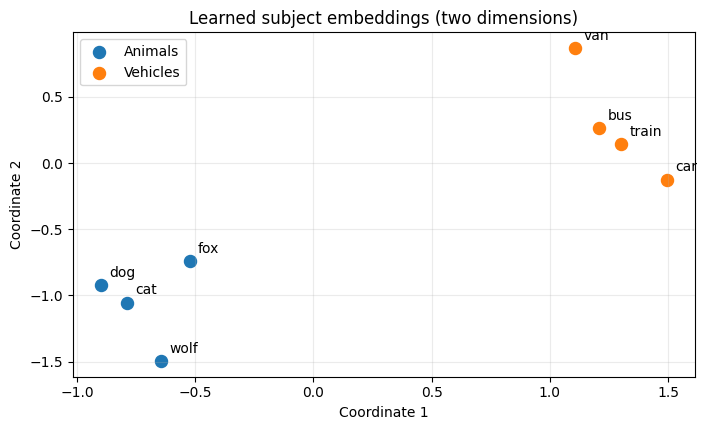

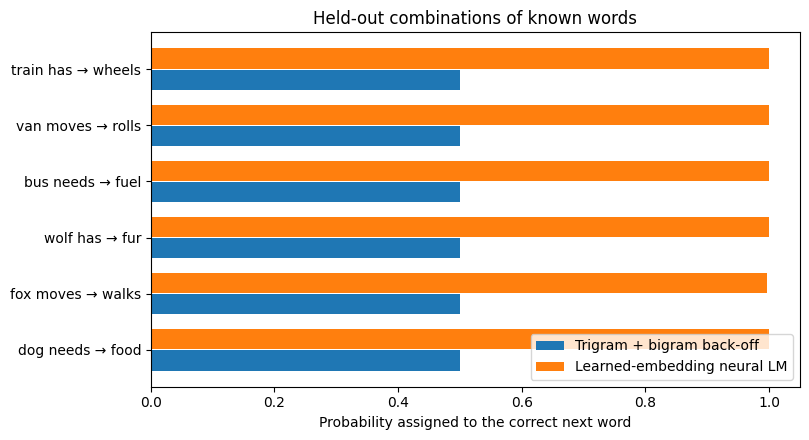

Saved: Mini_Bengio_embeddings.png and Mini_Bengio_probabilities.png


In [5]:
# Visualize the eight subject embeddings and the held-out predictions.
with torch.no_grad():
    embeddings = model.embed.weight.cpu().numpy()

fig, ax = plt.subplots(figsize=(7.2, 4.4))
for words, group in [(animals, 'Animals'), (vehicles, 'Vehicles')]:
    xy = np.array([embeddings[word_id[w]] for w in words])
    ax.scatter(xy[:, 0], xy[:, 1], s=75, label=group)
    for w, (x, y) in zip(words, xy):
        ax.annotate(w, (x, y), xytext=(6, 6), textcoords='offset points')
ax.set(title='Learned subject embeddings (two dimensions)', xlabel='Coordinate 1', ylabel='Coordinate 2')
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig('Mini_Bengio_embeddings.png', dpi=160)
plt.show()

labels = [f'{s} {r} → {w}' for s, r, w in test]
counts = [count_probability(s, r, w) for s, r, w in test]
neural_probs = [test_probs[i, word_id[w]] for i, (_, _, w) in enumerate(test)]
ypos = np.arange(len(test))
fig, ax = plt.subplots(figsize=(8.2, 4.5))
ax.barh(ypos - .19, counts, height=.36, label='Trigram + bigram back-off')
ax.barh(ypos + .19, neural_probs, height=.36, label='Learned-embedding neural LM')
ax.set(yticks=ypos, yticklabels=labels, xlim=(0, 1.05),
       xlabel='Probability assigned to the correct next word',
       title='Held-out combinations of known words')
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig('Mini_Bengio_probabilities.png', dpi=160)
plt.show()
print('Saved: Mini_Bengio_embeddings.png and Mini_Bengio_probabilities.png')


**Interpretation:** The original Bengio et al. model learns one embedding per vocabulary word and combines context embeddings with shared network parameters. This demo captures the idea of transfer to **unseen combinations of seen words**, not open-vocabulary understanding. A more sophisticated count-based model with learned word classes or additional rules could also generalize here; this toy experiment does **not** establish broad neural superiority.
